<a href="https://colab.research.google.com/github/codanixx/Laboratory-Exam/blob/main/Fajerga_LaboratoryExam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Upload and Load the Telecom Churn Dataset
Run the cell below to upload the downloaded file.

In [2]:
import io
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Scikit-Learn Preprocessing & Pipeline utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Scikit-Learn Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Scikit-Learn Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

# Trigger file upload
uploaded = files.upload()

# Load the uploaded CSV file
if uploaded:
    filename = list(uploaded.keys())[0]
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f"Loaded file: {filename}")
    display(df.head())
else:
    print("Please upload a file to proceed.")

Saving telecom_churn (1).csv to telecom_churn (1) (1).csv
Loaded file: telecom_churn (1) (1).csv


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Step 2: Data Preprocessing and Stratified Split
We will build a preprocessing pipeline using `scikit-learn` to handle numeric scaling, imputation of missing values, and categorical encoding. Then, we partition the dataset with stratification to preserve class balance.

In [3]:
# Identify potential target columns for churn
possible_targets = [col for col in df.columns if 'churn' in col.lower()]
if not possible_targets:
    raise ValueError("Could not find a target column with 'churn' in its name. Please rename your target column to 'churn'.")
target_col = possible_targets[0]
print(f"Target column identified: {target_col}")

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col].astype(bool) # Convert target class to True/False representation

# Define numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Create pipelines for preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Split data using 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Target column identified: churn
Training set shape: (2666, 20)
Testing set shape: (667, 20)


### Step 3: Model Implementation and Training
We instantiate Logistic Regression, Decision Tree Classifier, and Random Forest Classifier models, train them, and run predictions on the test set.

In [4]:
# Instantiate models as pipelines combining preprocessing and the model itself
models = {
    'Logistic Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Decision Tree': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(max_depth=5, random_state=42))
    ])
}

# Dictionary to store predictions and probabilities
results = {}

# Train and predict
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    results[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


### Step 4: Metrics Evaluation and Comparative Summary

In [5]:
metrics_summary = []

for name, outputs in results.items():
    y_pred = outputs['y_pred']
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    metrics_summary.append({
        'Model': name,
        'Accuracy': f"{acc:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'F1-Score': f"{f1:.4f}"
    })

summary_df = pd.DataFrame(metrics_summary)
display(summary_df)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8591,0.5333,0.2474,0.3380
1,Decision Tree,0.9175,0.7561,0.6392,0.6927
2,Random Forest,0.8546,0.0000,0.0000,0.0000


### Step 5: Plotting ROC Curves

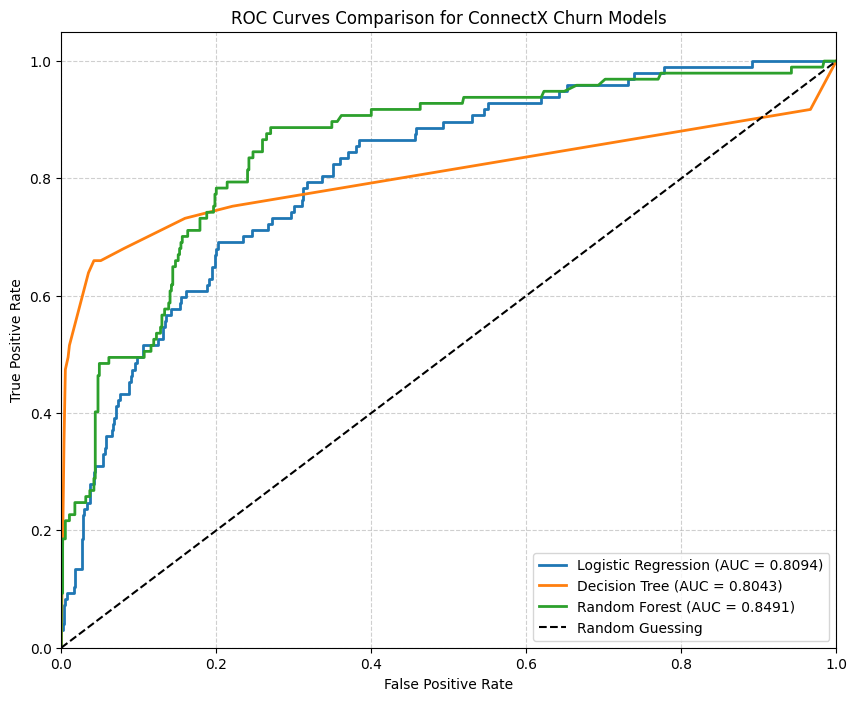

In [6]:
plt.figure(figsize=(10, 8))

for name, outputs in results.items():
    y_prob = outputs['y_prob']
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing', lw=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison for ConnectX Churn Models')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Step 5.5: Visualizing Confusion Matrices
To better understand where our classifiers are making errors, we will plot a side-by-side confusion matrix for each model. This will visually illustrate the count of True Negatives, False Positives, False Negatives, and True Positives.

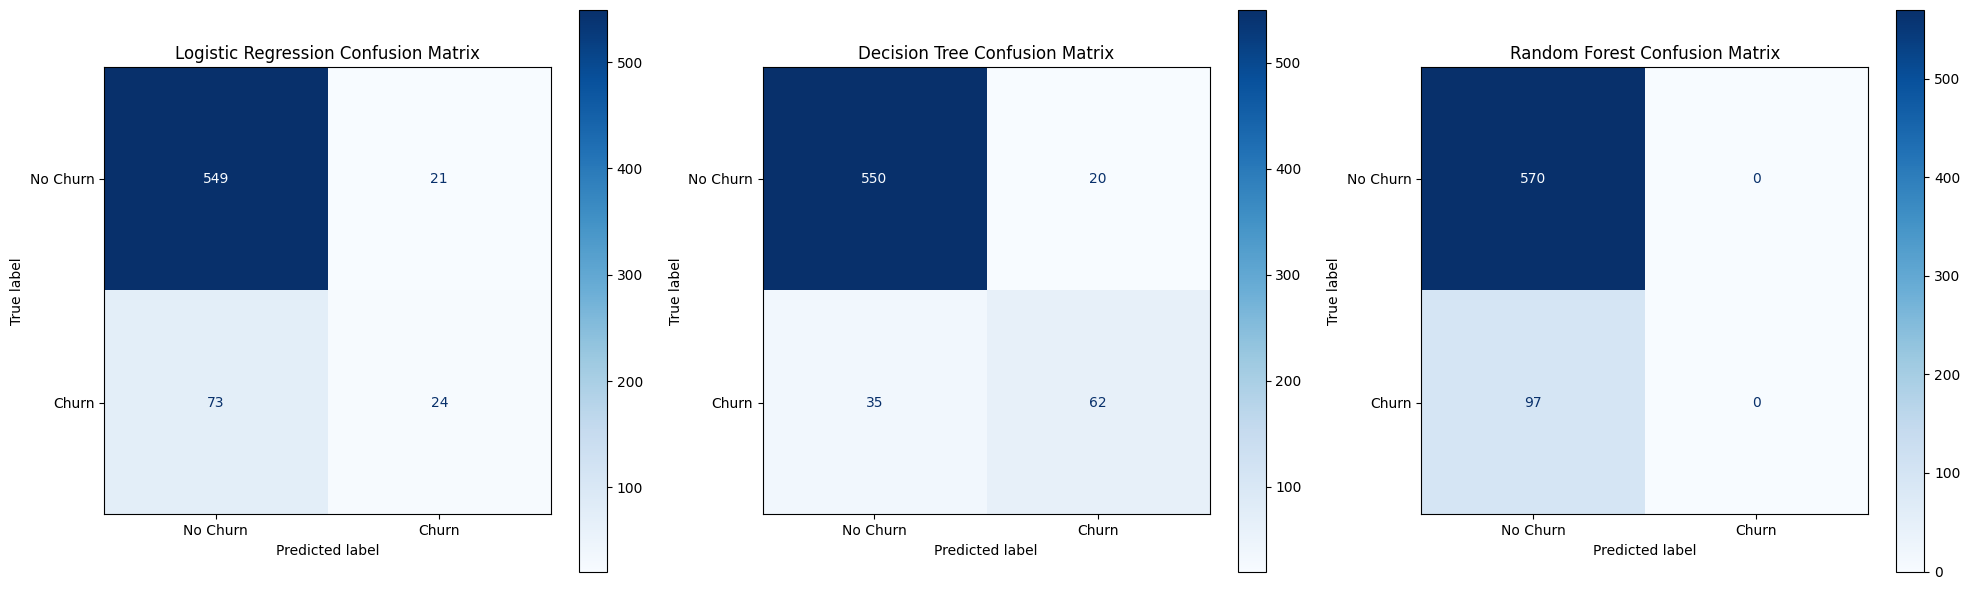

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Set up a side-by-side subplot figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, (name, outputs) in enumerate(results.items()):
    y_pred = outputs['y_pred']
    cm = confusion_matrix(y_test, y_pred)

    # Display the confusion matrix using standard scikit-learn helper
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].grid(False)

plt.tight_layout()
plt.show()